# Smog EDA: PM2.5 in four Pakistani cities
This notebook loads the clean data and shows the main EDA charts.
## 1. Load the data


In [ ]:
import sys
sys.path.append("../src")   # lets the notebook import files from src/

import pandas as pd
import matplotlib.pyplot as plt
import eda                  # our src/eda.py

df = eda.load_clean()
df.head()

,city,time,pm2_5,temperature,humidity,wind_speed,pressure,year,month,hour,season
0,Islamabad,2022-08-04 05:00:00,50.2,24.8,78.0,7.3,944.7,2022,8,5,Summer
1,Islamabad,2022-08-04 06:00:00,49.9,26.2,77.0,3.7,945.1,2022,8,6,Summer
2,Islamabad,2022-08-04 07:00:00,51.8,28.3,68.0,3.2,945.6,2022,8,7,Summer
3,Islamabad,2022-08-04 08:00:00,51.0,29.6,64.0,1.1,946.0,2022,8,8,Summer
4,Islamabad,2022-08-04 09:00:00,49.1,30.9,60.0,2.0,946.0,2022,8,9,Summer


## 2. PM2.5 by hour of day

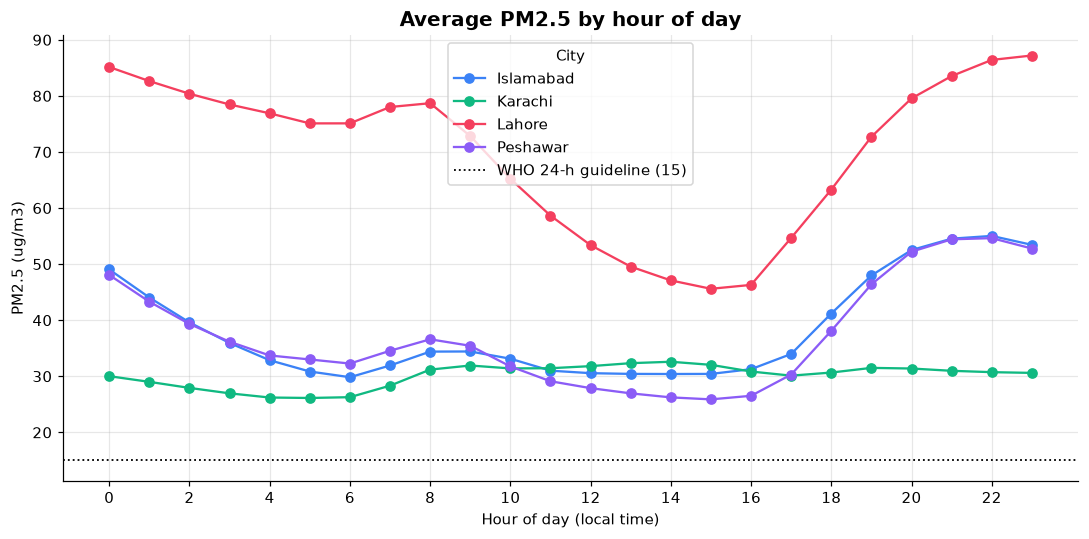

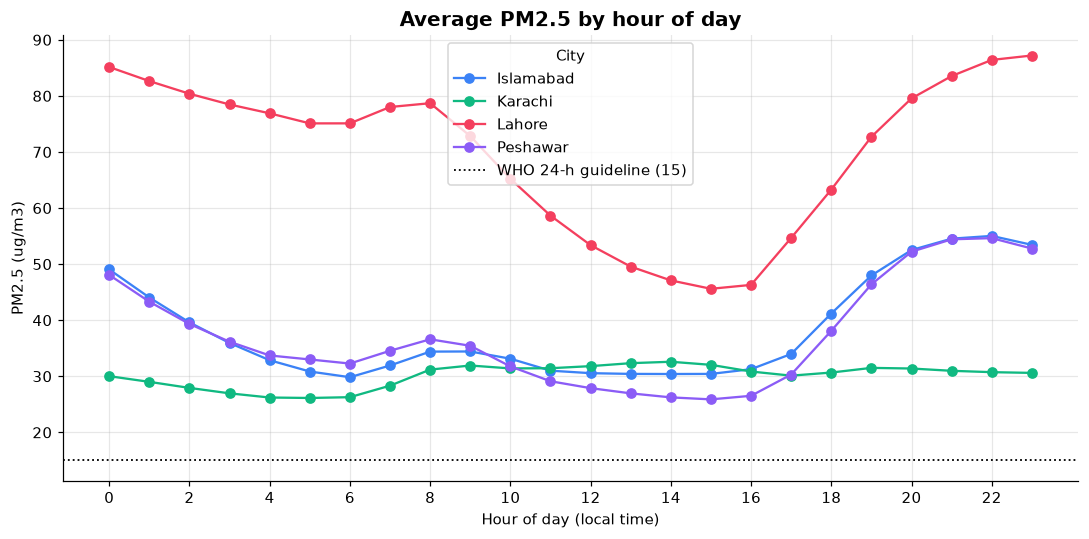

In [ ]:
eda.plot_hourly_by_city(df)

### Winter only

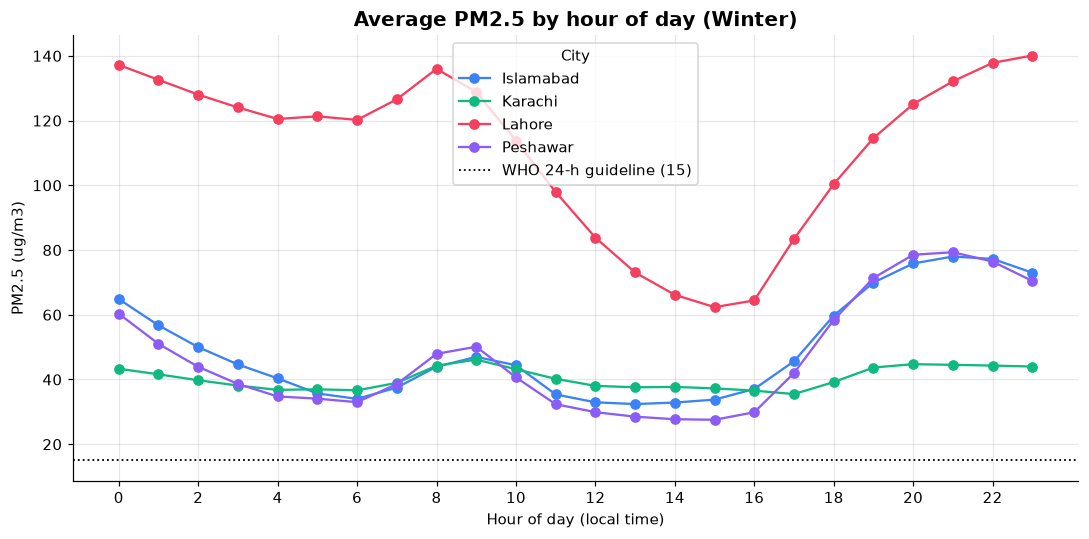

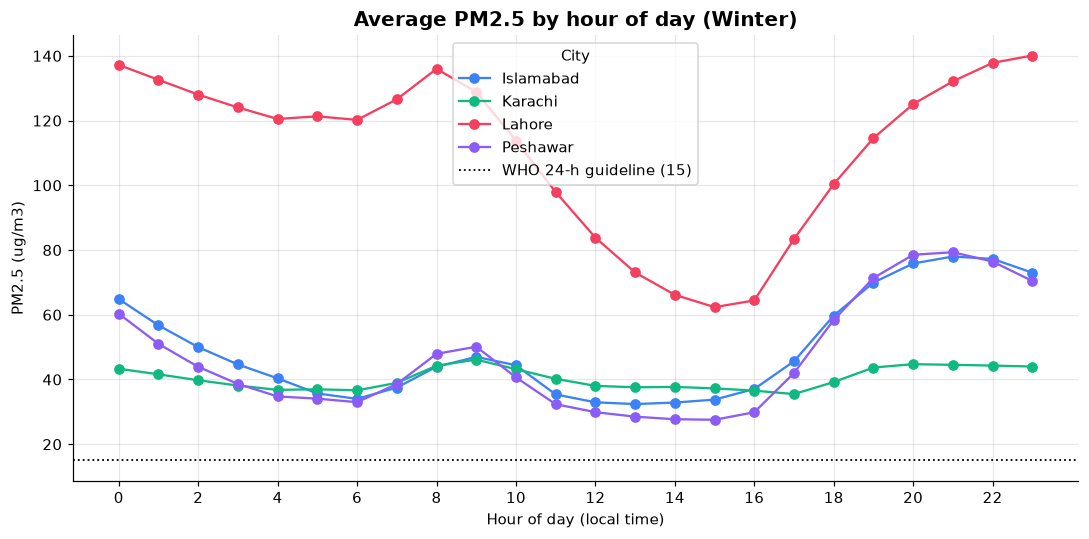

In [ ]:
eda.plot_hourly_by_city(df, season="Winter")

## 3. PM2.5 by month

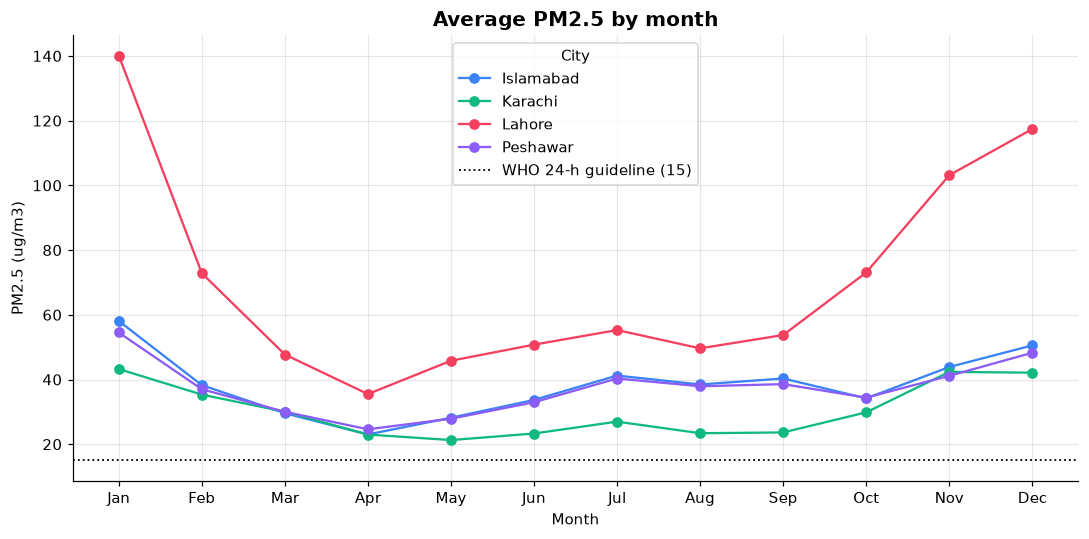

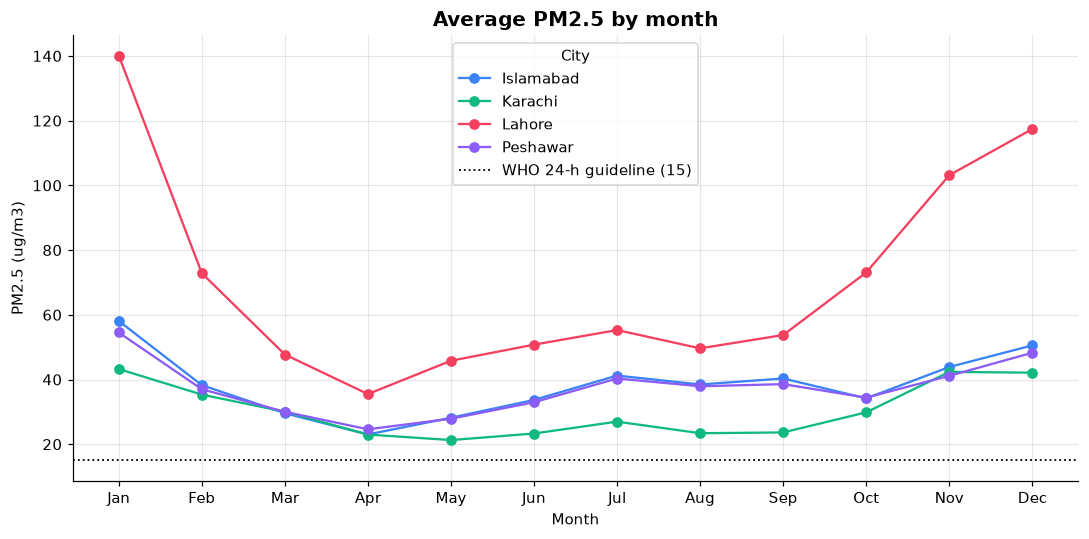

In [ ]:
eda.plot_monthly_by_city(df)

## 4. PM2.5 by season

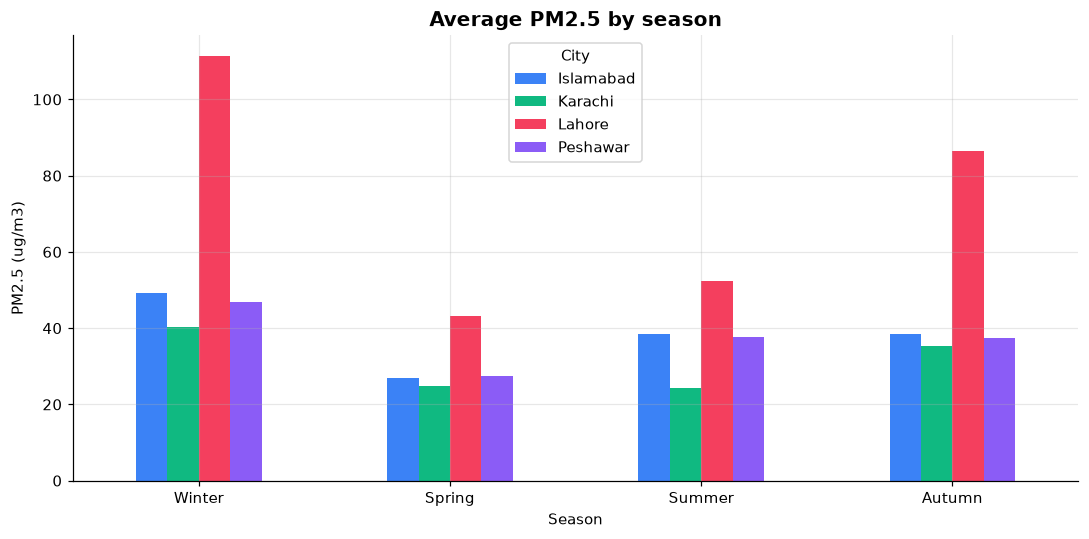

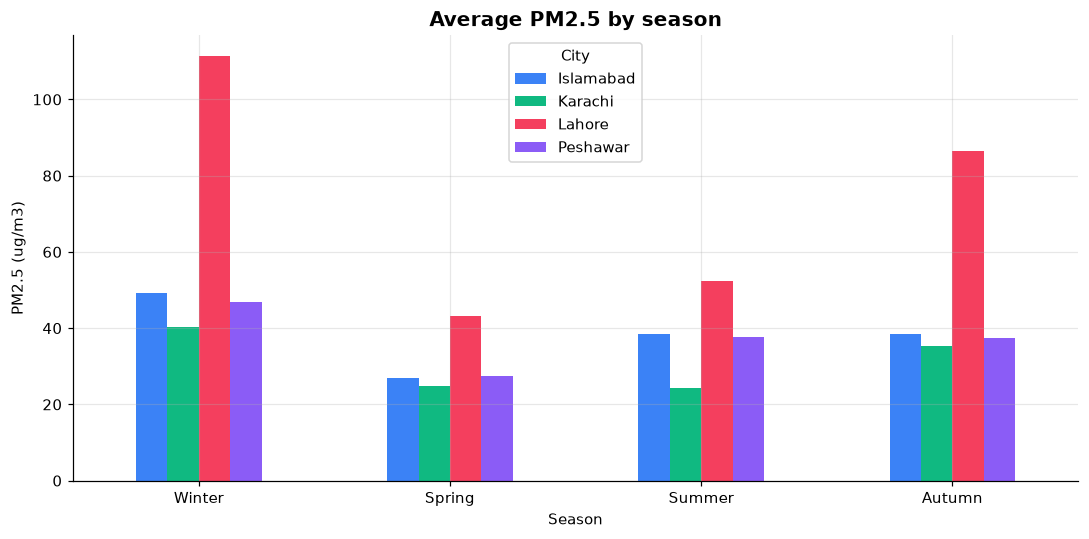

In [ ]:
eda.plot_season_by_city(df)

## 5. Weather and PM2.5

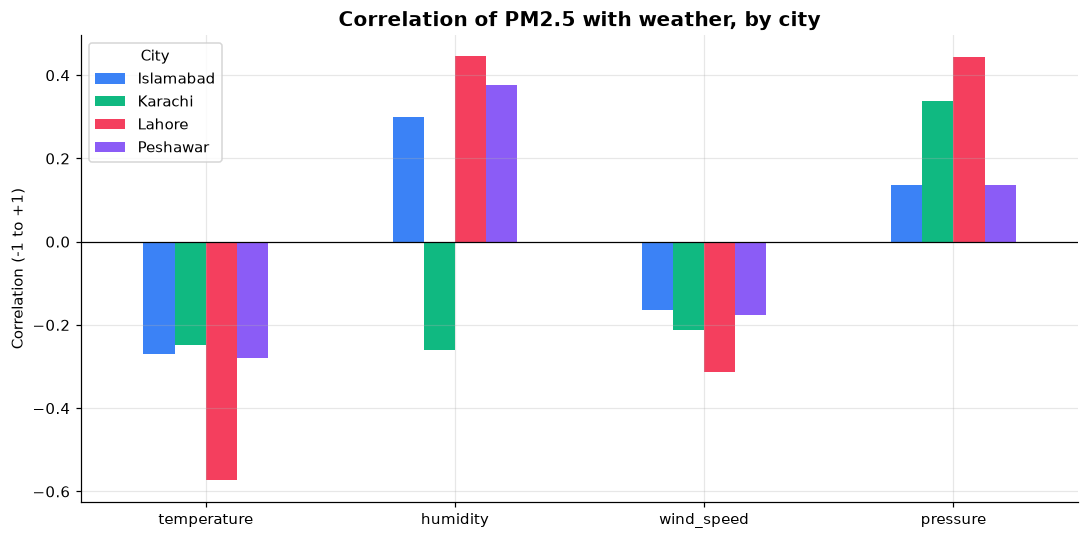

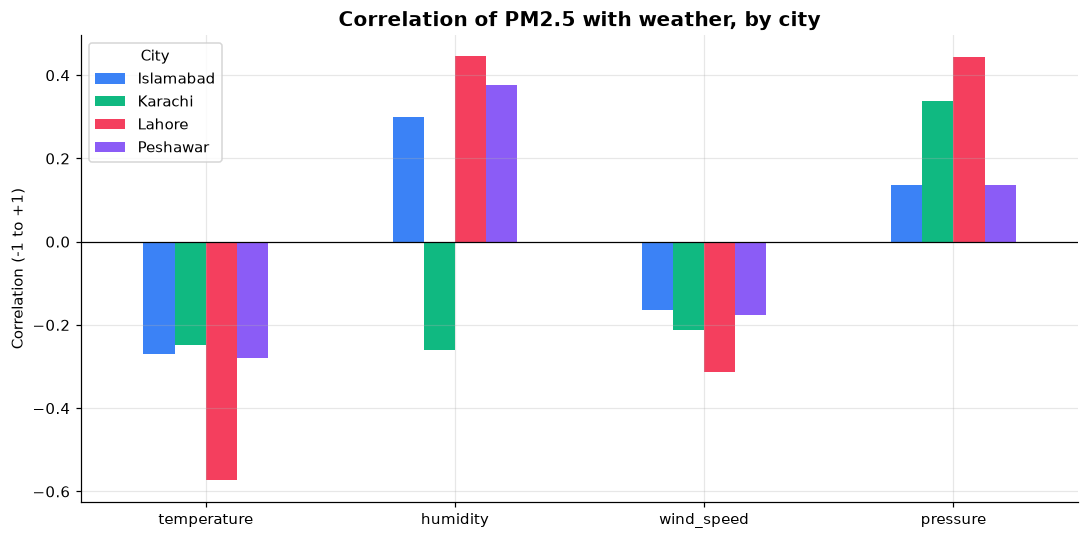

In [ ]:
eda.plot_weather_correlation_by_city(df)

### Correlation heatmap (Lahore)

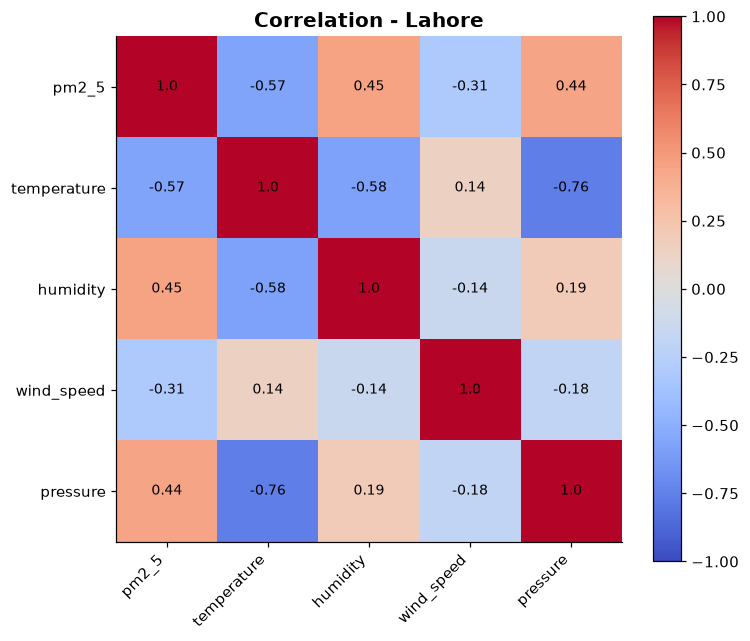

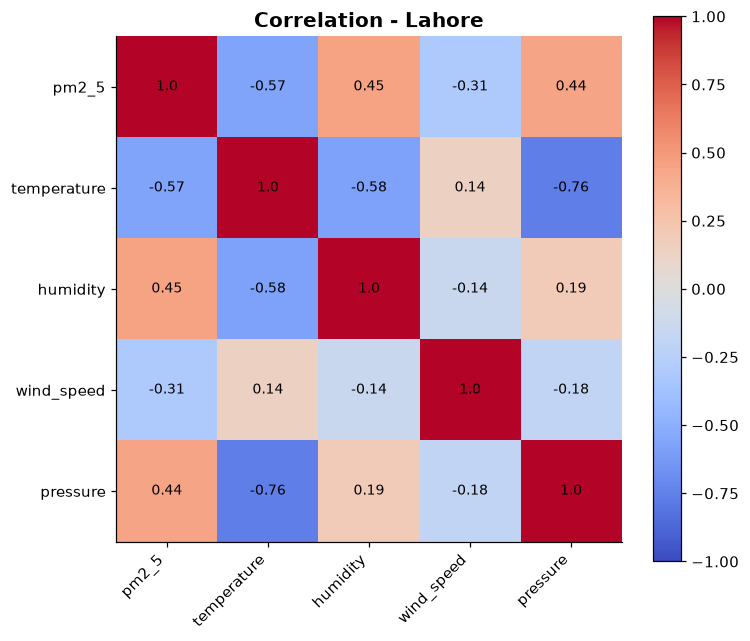

In [ ]:
eda.plot_correlation_heatmap(df, city="Lahore")

### Scatter: humidity

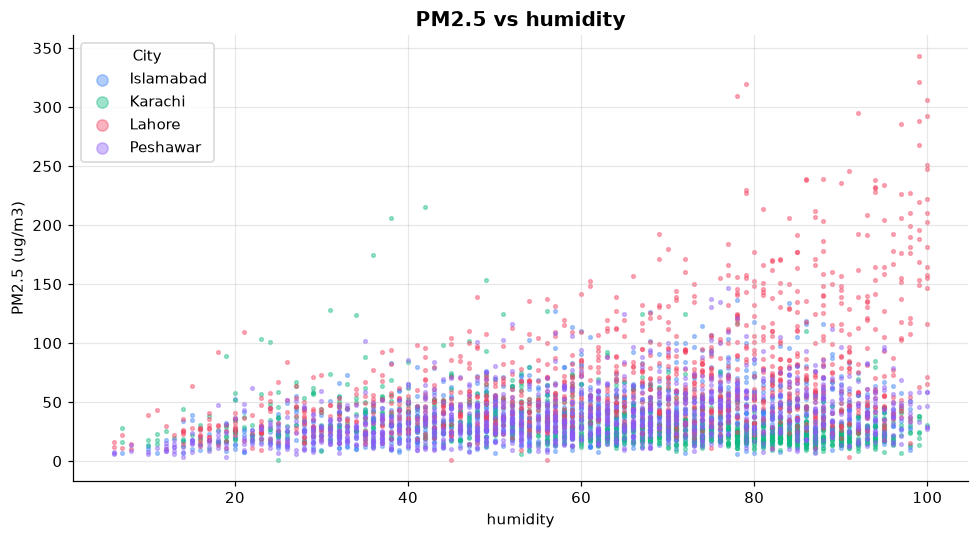

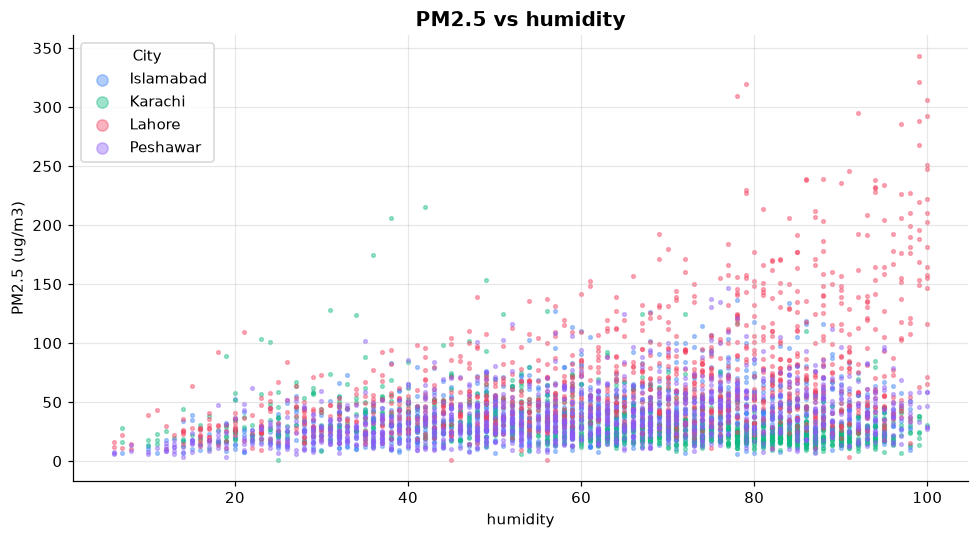

In [ ]:
eda.plot_weather_scatter(df, "humidity")

### Scatter: wind speed

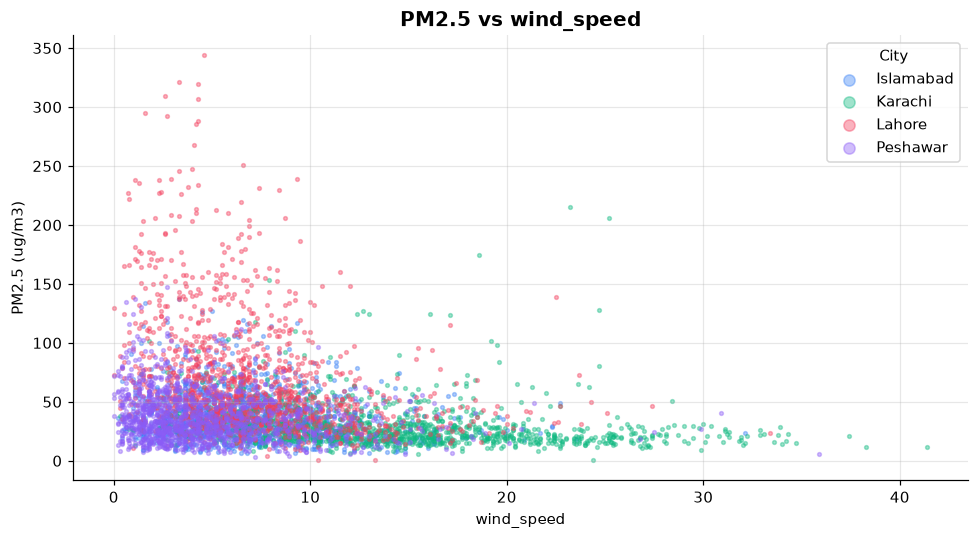

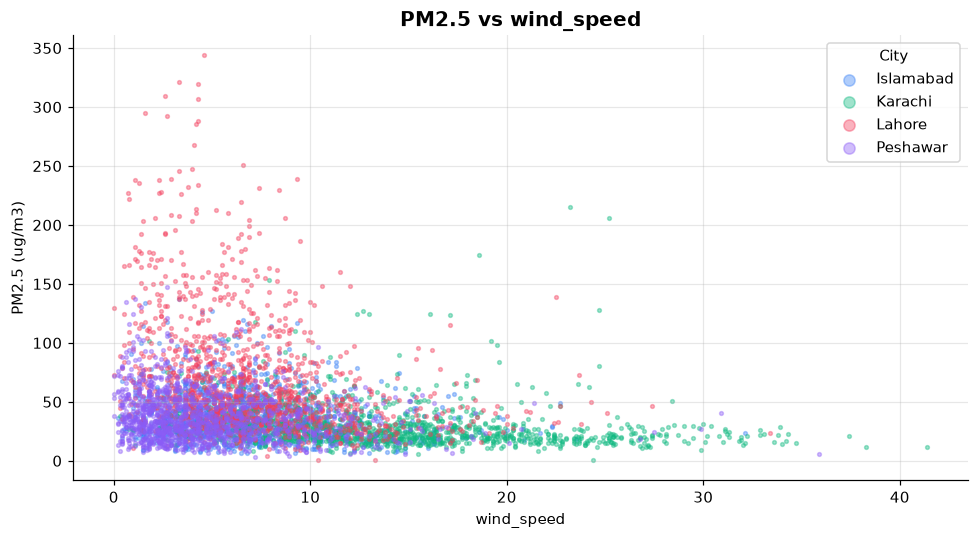

In [ ]:
eda.plot_weather_scatter(df, "wind_speed")

## 6. Autocorrelation and the tomorrow = today baseline

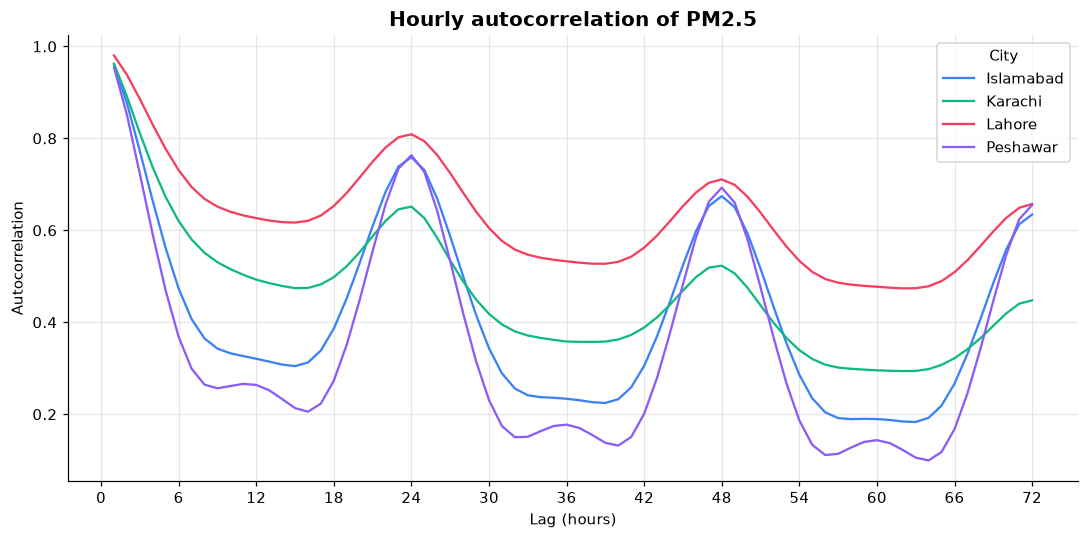

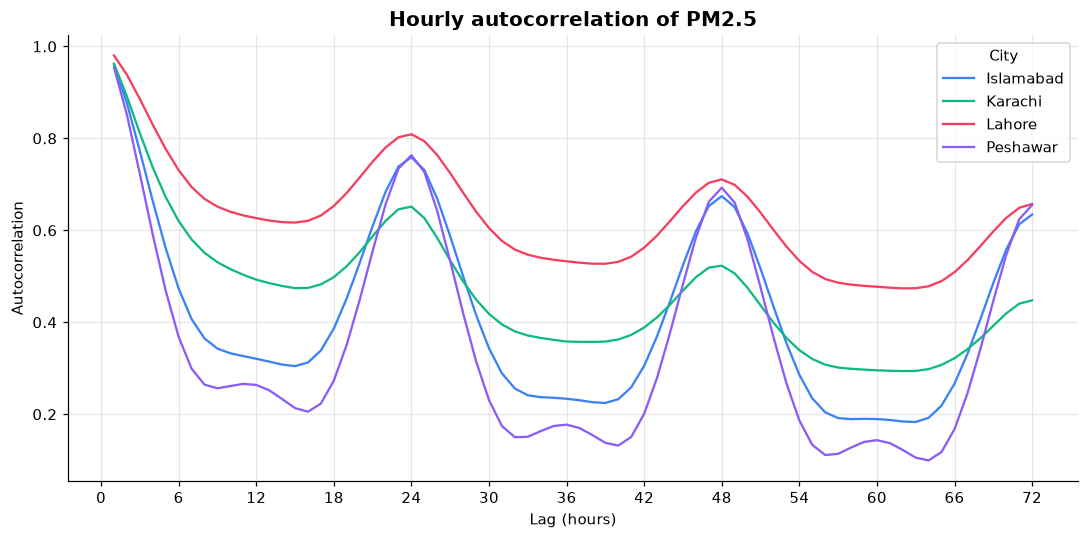

In [ ]:
eda.plot_autocorrelation(df)

### Daily autocorrelation

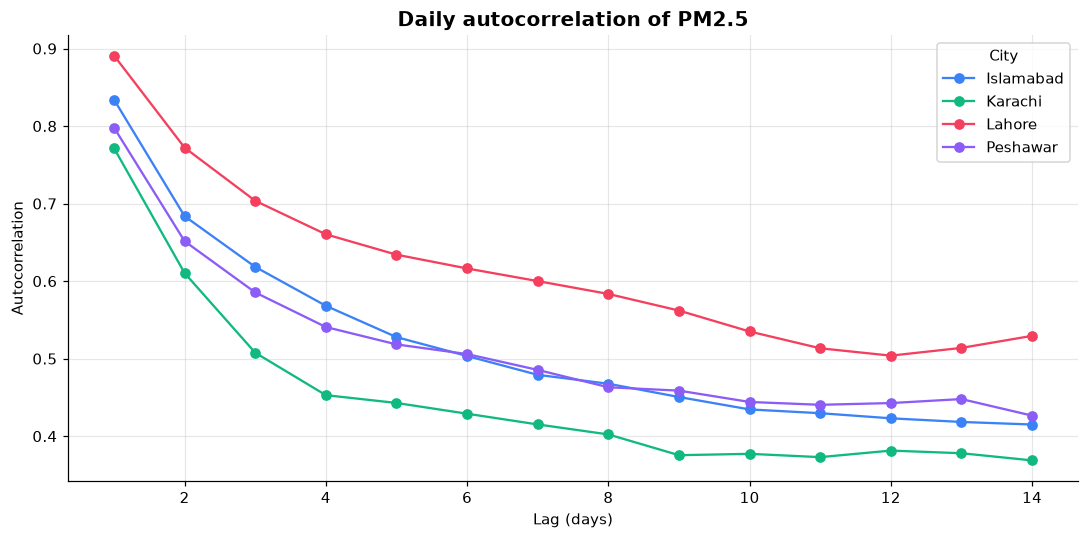

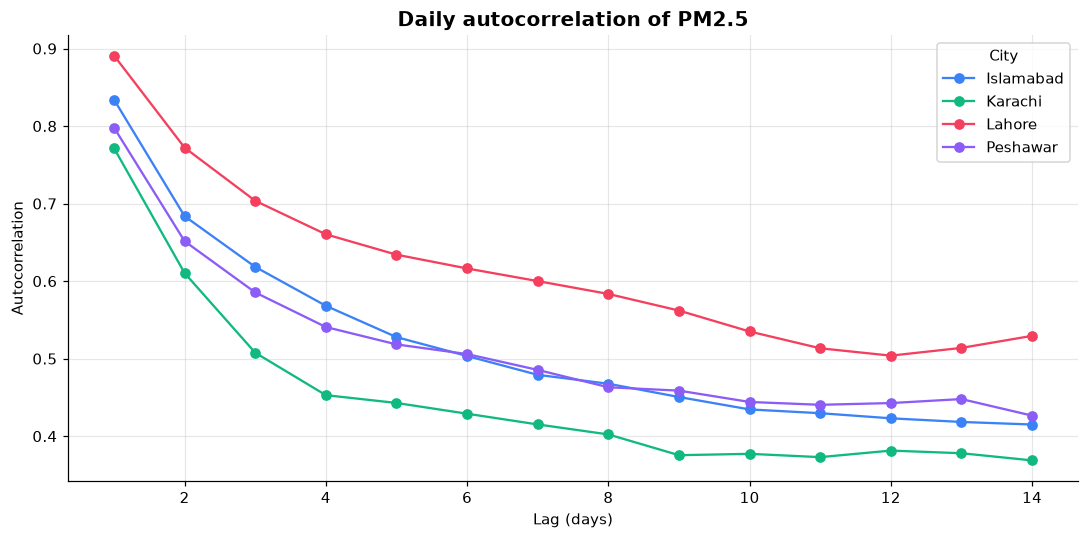

In [ ]:
eda.plot_daily_autocorrelation(df)

### Baseline: tomorrow = today

In [ ]:
eda.persistence_baseline(df)

,city,correlation_today_vs_tomorrow,mean_abs_error
0,Islamabad,0.83,6.3
1,Karachi,0.77,6.1
2,Lahore,0.89,13.5
3,Peshawar,0.80,6.5


## 7. Extreme PM2.5 values

In [ ]:
karachi = df[df["city"] == "Karachi"]

# The 10 highest PM2.5 hours in Karachi
karachi.nlargest(10, "pm2_5")[["time", "pm2_5", "wind_speed", "humidity"]]

,time,pm2_5,wind_speed,humidity
37253,2022-08-10 15:00:00,448.9,13.4,83.0
37252,2022-08-10 14:00:00,430.3,15.8,80.0
37254,2022-08-10 16:00:00,353.9,13.5,91.0
42293,2023-03-08 15:00:00,339.0,20.1,51.0
37277,2022-08-11 15:00:00,323.2,18.0,82.0
37251,2022-08-10 13:00:00,299.9,9.5,91.0
37278,2022-08-11 16:00:00,297.1,16.9,92.0
41478,2023-02-02 16:00:00,290.6,17.8,35.0
42294,2023-03-08 16:00:00,279.4,22.9,48.0
37276,2022-08-11 14:00:00,277.5,23.4,63.0


In [ ]:
# How many separate days do the 50 highest hours come from?
karachi.nlargest(50, "pm2_5")["time"].dt.date.value_counts().sort_index()

time
2022-08-09    1
2022-08-10    5
2022-08-11    4
2022-09-10    4
2022-09-12    1
2022-10-09    4
2022-10-23    2
2023-01-08    1
2023-01-10    1
2023-02-02    6
2023-02-07    4
2023-02-18    2
2023-03-05    1
2023-03-06    2
2023-03-07    1
2023-03-08    5
2023-03-09    4
2023-03-10    2
Name: count, dtype: int64

In [ ]:
# Highest PM2.5 of each city in each year
df.groupby(["city", "year"])["pm2_5"].max().unstack().round(0)

year,2022,2023,2024,2025,2026
city,,,,,
Islamabad,122.0,152.0,171.0,140.0,146.0
Karachi,449.0,339.0,92.0,109.0,96.0
Lahore,319.0,321.0,365.0,326.0,354.0
Peshawar,112.0,134.0,151.0,156.0,156.0


## 8. Data overview, quality checks and distributions

### Overview per city

In [ ]:
eda.overview(df)

,rows,start,end,avg_pm25,max_pm25
city,,,,,
Islamabad,37099,2022-08-04 05:00:00,2026-10-27 23:00:00,38.3,170.9
Karachi,37099,2022-08-04 05:00:00,2026-10-27 23:00:00,30.1,448.9
Lahore,37099,2022-08-04 05:00:00,2026-10-27 23:00:00,69.9,365.1
Peshawar,37099,2022-08-04 05:00:00,2026-10-27 23:00:00,37.3,156.5


### Data quality checks
Every check should be 0.

In [ ]:
eda.quality_checks(df)

,check,result
0,Duplicate rows (same city and hour),0
1,Missing values (all columns),0
2,Impossible pm2_5 values,0
3,Impossible temperature values,0
4,Impossible humidity values,0
5,Impossible wind_speed values,0
6,Impossible pressure values,0
7,Missing hours (time gaps),0


### Rows per year

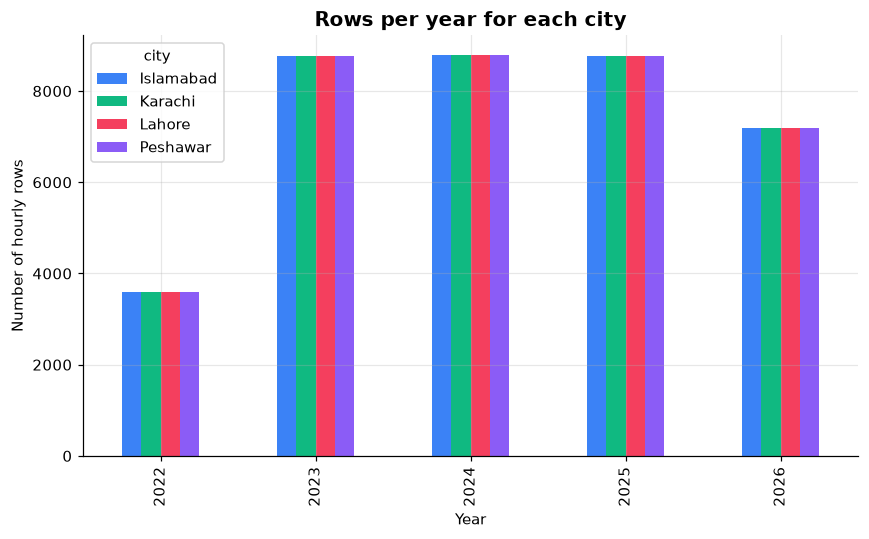

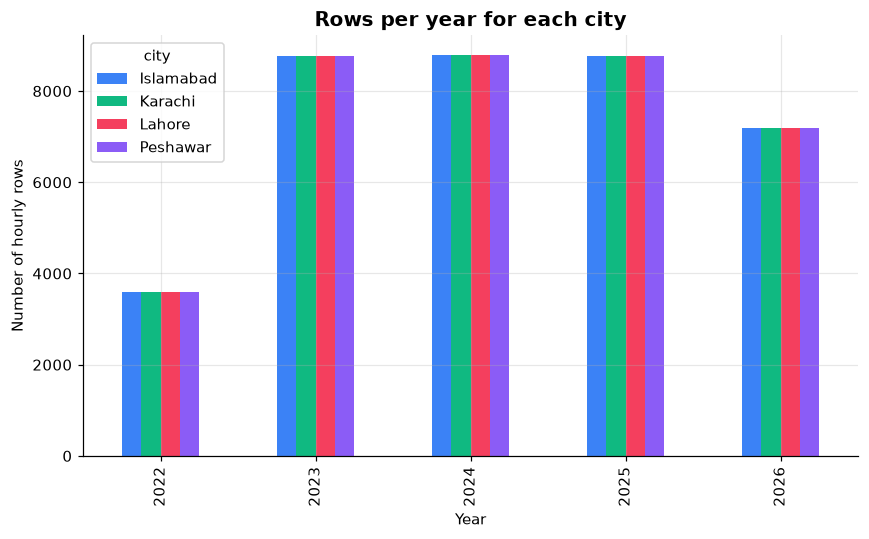

In [ ]:
eda.plot_rows_per_year(df)

### Distribution of each variable

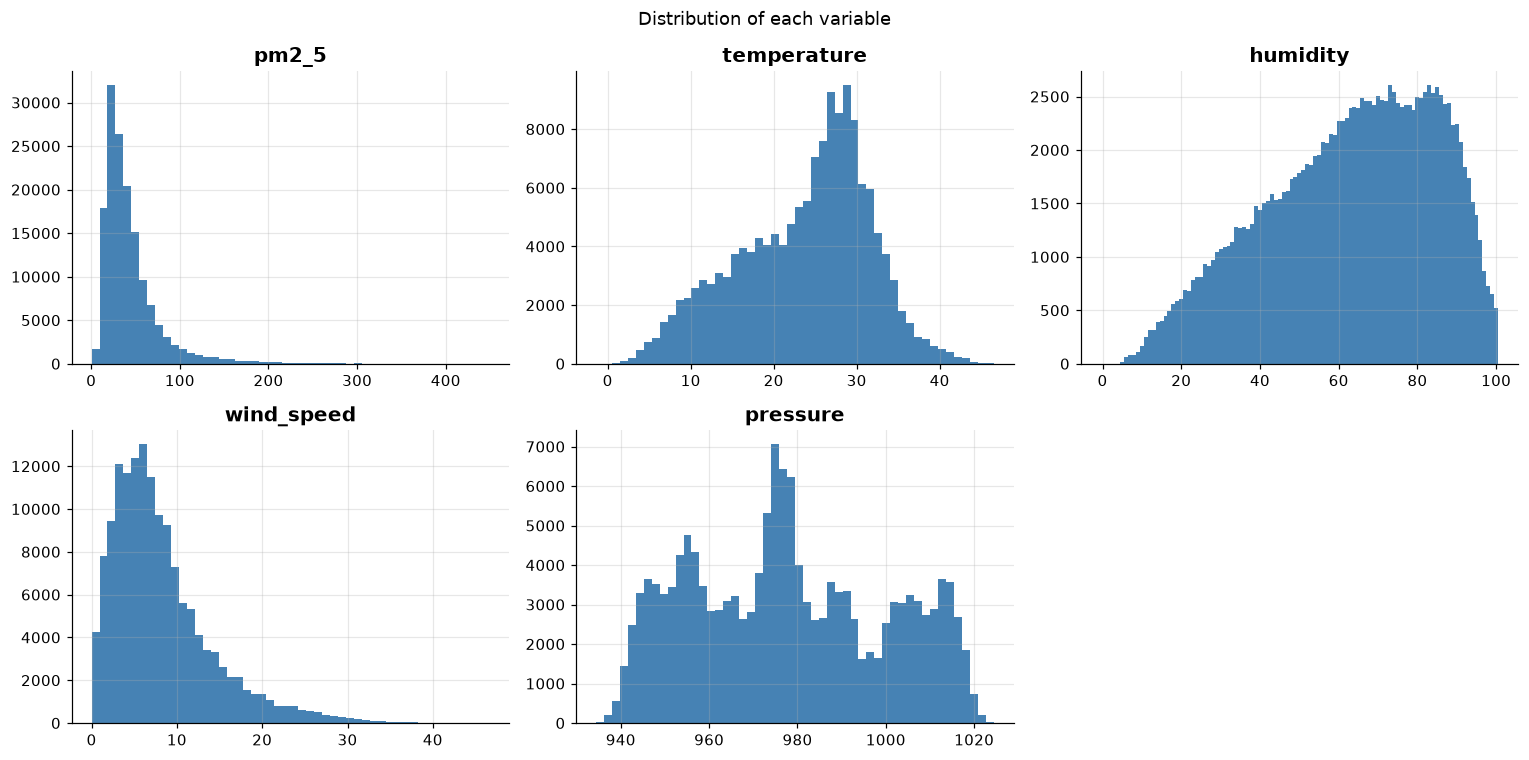

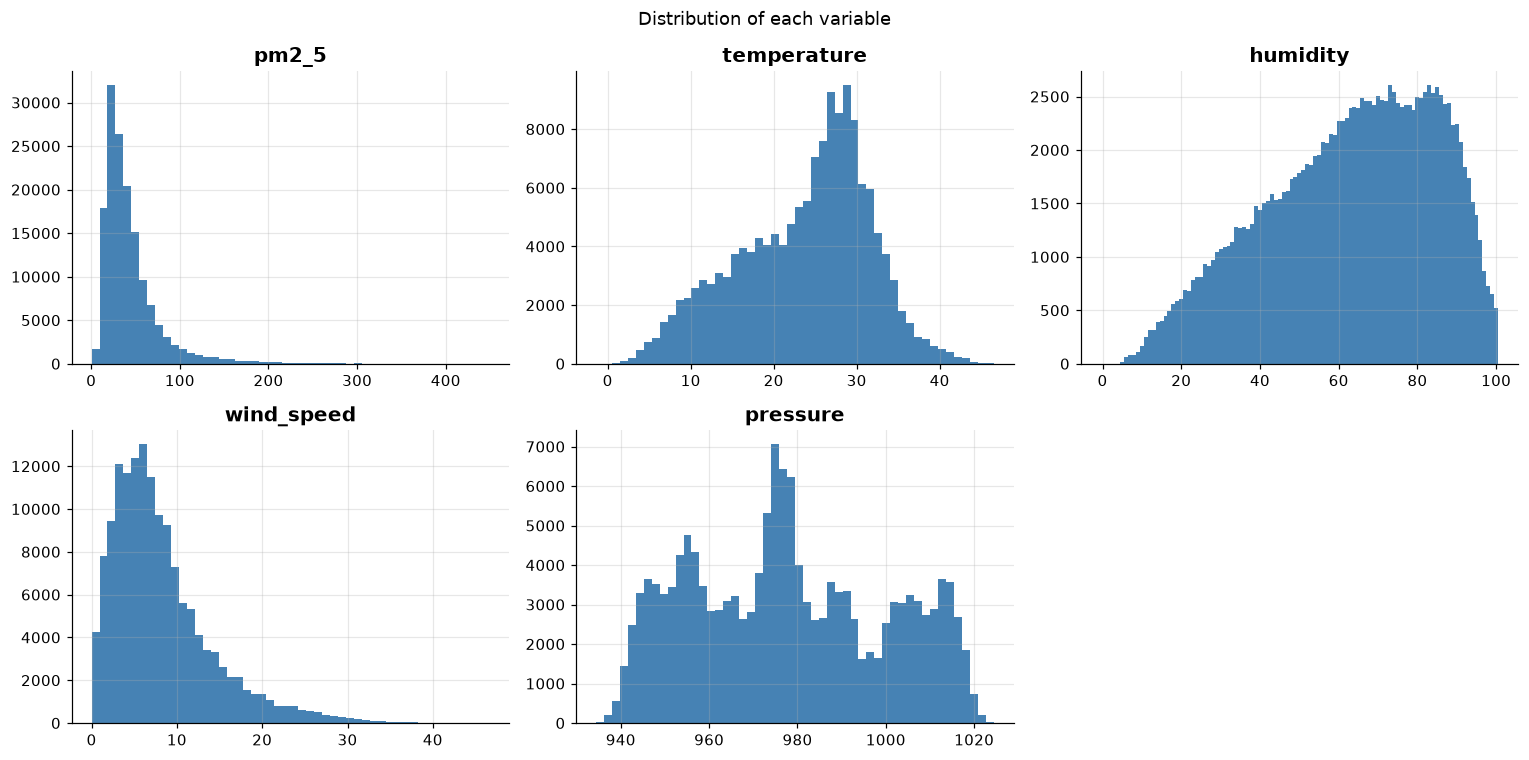

In [ ]:
eda.plot_histograms(df)

### PM2.5 by city (box plot)

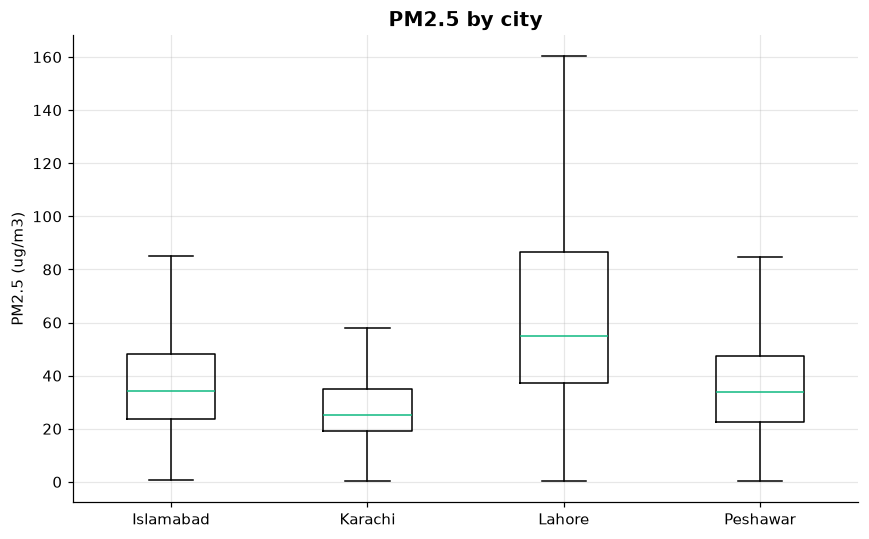

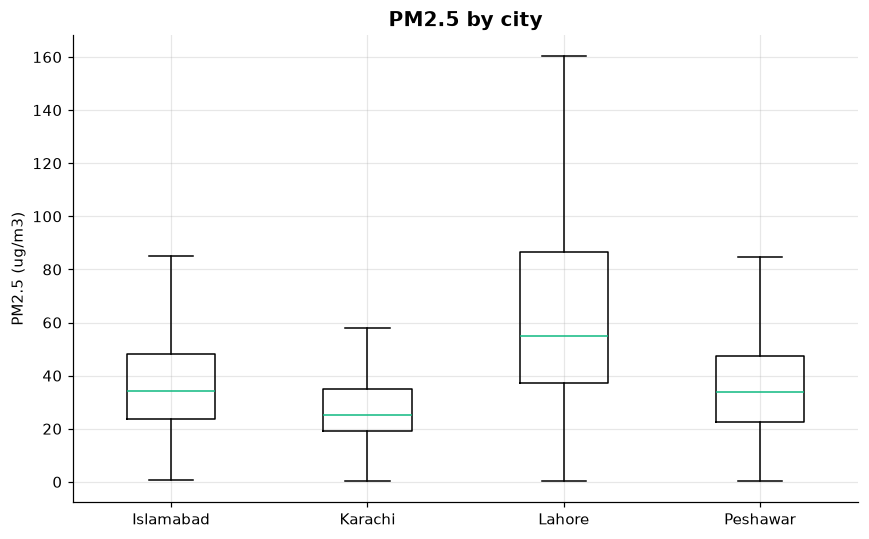

In [ ]:
eda.plot_pm25_by_city(df)